# Tier 2 Model: Random Forest on TF-IDF

This notebook trains a Random Forest on the same TF-IDF features and train/test split as the Logistic Regression baseline, then explains it with post-hoc methods because, unlike the baseline, a forest of many trees is not transparent by design.

The explanation steps follow the course's interpretation pipeline: global importance (PFI / SHAP) → feature effects (PDP) → heterogeneity (ICE) → individual decisions (LIME / SHAP) → domain validation and audit.


## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score, accuracy_score
)
from sklearn.inspection import PartialDependenceDisplay

from lime.lime_text import LimeTextExplainer
import shap

from preprocessing import (
    preprocess_text, get_tfidf_features,
    get_train_test_split, select_top_k_terms, RANDOM_STATE
)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,Foreign Democrat final.,more tax development both store agreement lawy...,real,0
1,To offer down resource great point.,probably guess western behind likely next inve...,fake,1
2,Himself church myself carry.,them identify forward present success risk sev...,fake,1
3,You unit its should.,phone which item yard Republican safe where po...,fake,1
4,Billion believe employee summer how.,wonder myself fact difficult course forget exa...,fake,1


## 3. Text Preprocessing

In [3]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df[["full_text", "processed_text"]].head()

,full_text,processed_text
0,Foreign Democrat final. more tax development b...,foreign democrat final tax development store a...
1,To offer down resource great point. probably g...,offer resource great point probably guess west...
2,Himself church myself carry. them identify for...,church carry identify forward present success ...
3,You unit its should. phone which item yard Rep...,unit phone item yard republican safe police id...
4,Billion believe employee summer how. wonder my...,billion believe employee summer wonder fact di...


Quick check: compare one raw vs. processed example side by side.

In [4]:
print("RAW:\n", df["full_text"].iloc[0][:300])
print("\nPROCESSED:\n", df["processed_text"].iloc[0][:300])

RAW:
 Foreign Democrat final. more tax development both store agreement lawyer hear outside continue reach difference yeah figure your power fear identify there protect security great national nothing fast story why late nearly bit cost tough since question to power almost future young conference behind a

PROCESSED:
 foreign democrat final tax development store agreement lawyer hear outside continue reach difference yeah figure power fear identify protect security great national nothing fast story late nearly bit cost tough since question power almost future young conference behind ahead building teach million b


## 4. TF-IDF Vectorization

In [5]:
X, y, tfidf = get_tfidf_features(df)
feature_names = tfidf.get_feature_names_out()

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (20000, 867)


## 5. Train/Test Split

In [6]:
X_train, X_test, y_train, y_test = get_train_test_split(X, y)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (16000, 867)
Test shape: (4000, 867)

Train class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64

Test class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64


## 6. Train Random Forest

Tree depth and leaf size are capped. This keeps the forest smaller (more interpretable, much faster to explain with TreeSHAP) and limits overfitting.

In [7]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

## 7. Validate Predictive Performance

In [8]:
print(classification_report(y_test, y_pred, target_names=["real", "fake"]))

recall_fake = recall_score(y_test, y_pred, pos_label=1)
accuracy = accuracy_score(y_test, y_pred)
train_recall = recall_score(y_train, rf.predict(X_train), pos_label=1)

print(f"Fake-class recall (test):  {recall_fake:.4f}")
print(f"Fake-class recall (train): {train_recall:.4f}   <- large gap vs test = overfitting")
print(f"Accuracy (test): {accuracy:.4f}")

              precision    recall  f1-score   support

        real       0.50      0.46      0.48      1989
        fake       0.50      0.54      0.52      2011

    accuracy                           0.50      4000
   macro avg       0.50      0.50      0.50      4000
weighted avg       0.50      0.50      0.50      4000

Fake-class recall (test):  0.5370
Fake-class recall (train): 0.9995   <- large gap vs test = overfitting
Accuracy (test): 0.4998


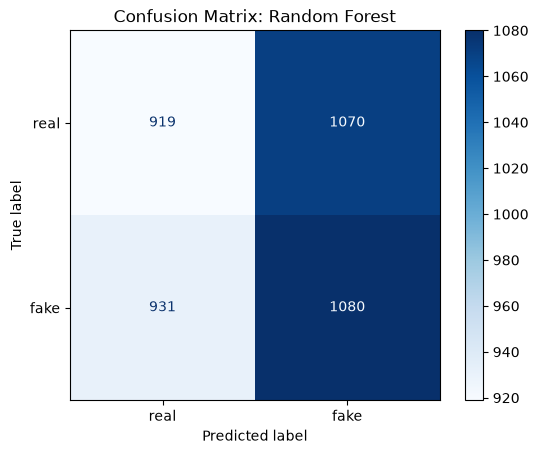

In [9]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["real", "fake"]).plot(cmap="Blues")
plt.title("Confusion Matrix: Random Forest")
plt.show()

- True Positive, correctly caught fake news article: 1,080
- False Negative, fake news article predicted as real: 931
- False Positive, real article predicted as fake: 1,070
- True Negative, correctly identified real article: 919

With a Fake-class recall of only ~54% (0.5370, display above) and an accuracy of ~50%, the Random Forest performs only marginally better than random guessing. It misses 41 fewer fake articles than the TF-IDF Logistic Regression baseline (931 vs. 972), but it also wrongly flags 1,070 real articles as fake, slightly more than the baseline (1,036), so the gain in recall comes without any gain in overall accuracy. Roughly 46% of fake articles still slip through undetected, which is not reliable enough to support a trust-and-safety reviewer's decision. The added complexity of a black-box model bought only a small gain, which suggests the text carries limited learnable signal regardless of the model used.

## 8. Top-K Terms and Multicollinearity Check

The full TF-IDF matrix has 5,000 terms, which is too many to inspect one by one. PFI would have to shuffle every column, PDP/ICE would need thousands of plots, and a 5,000 x 5,000 correlation matrix cannot be read. So we construct the top-K terms (K = 30), the terms most associated with the fake/real label according to a chi-squared score. The scores use training data only, so the test labels never influence which terms are chosen.

Chi-squared is a statistical score that measures how strongly a term is associated with the label. For each term, it compares how much of that term's TF-IDF weight falls in fake articles versus real articles, and checks whether the split differs from what we would expect if the term had nothing to do with the label. A higher score means a stronger association. It does not tell us which direction the term points (fake or real).

We chose chi-squared because it does not depend on any model, so every model can share the same top-K list and be compared fairly. It is also fast, gives the same answer every run, and works with TF-IDF because the weights are never negative. Since TF-IDF weights are continuous rather than counts, the scores are used only to rank terms, not as formal significance tests.

In [10]:
K = 30
top_idx, top_terms, top_scores = select_top_k_terms(X_train, y_train, feature_names, k=K, method="chi2")
pd.DataFrame({"term": top_terms, "chi2_score": top_scores}).head(7)

,term,chi2_score
0,economy,0.576492
1,particular,0.551777
2,significant,0.531097
3,model,0.517952
4,girl,0.503255
5,bring,0.501048
6,reflect,0.499708


The table above shows the seven terms with the highest chi-squared scores, meaning the terms most strongly associated with the fake/real label in the training data. The terms (economy, particular, significant, model, girl, bring, reflect) are ordinary words rather than sensational or emotionally charged language, and the scores are low and close together (about 0.50 to 0.58), so no single term stands out. The table also does not say whether a term points toward fake or real.

All 30 terms are used in the analysis below, but only 7 are displayed at a time. Human working memory can hold about 7 ± 2 items at once, so limiting each table and plot to about 7 items lets the reader take it in at a glance without being overloaded.

In [11]:
X_test_dense = X_test.toarray().astype(np.float32)

rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(X_test_dense.shape[0], size=500, replace=False)
X_sample = X_test_dense[sample_idx]          # 500-row sample for PDP/ICE and SHAP

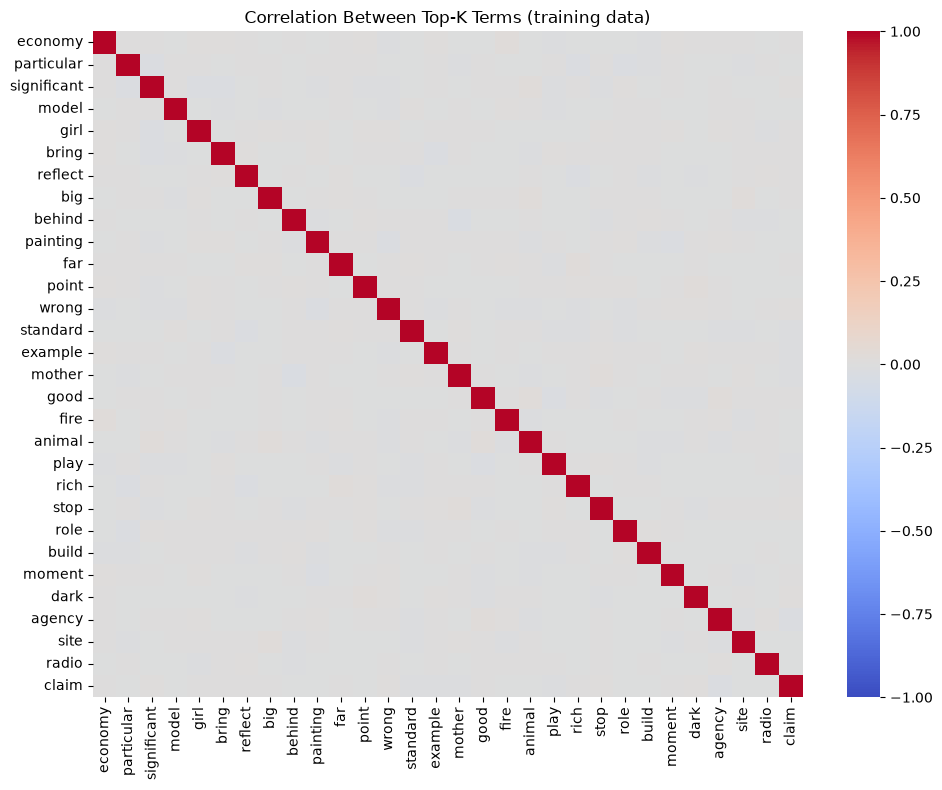

Pairs with |correlation| > 0.5:
Series([], dtype: float64)


In [12]:
X_train_topk = pd.DataFrame(X_train[:, top_idx].toarray(), columns=top_terms)
corr = X_train_topk.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Between Top-K Terms (training data)")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Pairs with |correlation| > 0.5:")
print(pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False))

The correlation heatmap checks whether any of the top-K terms move together across the training articles. Each cell shows the correlation between the TF-IDF weights of two terms, where 1 means they rise and fall together, -1 means one rises when the other falls, and 0 means no relationship. We also search for any pair above 0.5. This matters because the result decides which feature-effect technique we use later: PDP changes one term while holding the others fixed, which is only safe if the terms are not dependent on each other, and related terms can also split importance between them, which would distort PFI.

The heatmap is almost entirely pale gray, meaning the correlations between different terms are close to 0. The only strong cells are the red diagonal, which is each term compared with itself and is always 1. There are no red or blue cells off the diagonal, so none of the top 30 terms tends to appear together with, or instead of, another. This tells us the terms are close to independent of each other, so PDP can be used without creating unrealistic articles, and PFI should not be splitting importance between related terms. This check covers only the top 30 terms and only linear relationships, so it does not rule out every possible dependence, but it gives no reason to switch to ALE.

## 9. Global Importance (PFI and TreeSHAP)

### 9.1 Permutation Feature Importance (PFI)

Each top-K term is shuffled in the test set and the drop in Fake-class recall is measured (5 repeats). A large drop means the model relies on that term.

In [13]:
def permutation_recall_drop(model, X_dense, y_true, col_indices, n_repeats=5, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    base = recall_score(y_true, model.predict(X_dense), pos_label=1)
    rows = []
    for col in col_indices:
        original = X_dense[:, col].copy()
        drops = []
        for _ in range(n_repeats):
            X_dense[:, col] = rng.permutation(original)
            drops.append(base - recall_score(y_true, model.predict(X_dense), pos_label=1))
        X_dense[:, col] = original
        rows.append((feature_names[col], np.mean(drops), np.std(drops)))
    result = pd.DataFrame(rows, columns=["term", "mean_recall_drop", "std"])
    return base, result.sort_values("mean_recall_drop", ascending=False)

base_recall, pfi_df = permutation_recall_drop(rf, X_test_dense, y_test, top_idx)
print(f"Recall before shuffling: {base_recall:.4f}")
pfi_df.head(7)

Recall before shuffling: 0.5370


,term,mean_recall_drop,std
0,economy,0.003481,0.003613
28,radio,0.003481,0.002179
19,play,0.002984,0.001634
11,point,0.002486,0.001694
15,mother,0.002287,0.002624
9,painting,0.001989,0.001634
4,girl,0.001890,0.001585


The table above shows how much the Random Forest's Fake-class recall drops when each term is shuffled, starting from an unshuffled recall of 0.5370. The drops are very small: the largest, for economy and radio, is about 0.0035, which is roughly 7 of the 2,011 fake articles in the test set, and the smallest shown is about 3 articles. For most terms the drop is no larger than twice its standard deviation, and for economy and mother it is about the same size as the standard deviation, so these differences cannot be clearly separated from random variation between repeats. This means the model does not depend heavily on any single term, and the ranking among them should not be read closely. It is consistent with the weak performance seen earlier, where the text carries only a small amount of signal spread across many terms.

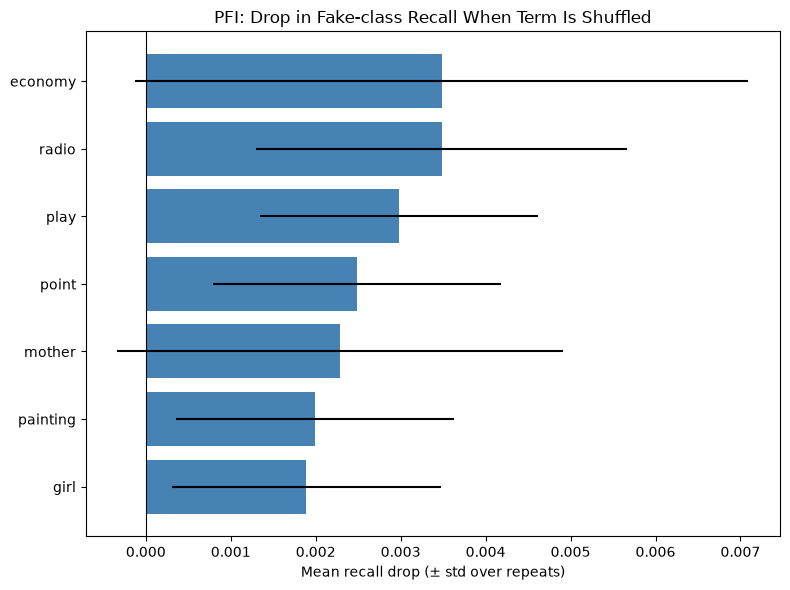

In [14]:
top_pfi = pfi_df.head(7).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top_pfi["term"], top_pfi["mean_recall_drop"], xerr=top_pfi["std"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("PFI: Drop in Fake-class Recall When Term Is Shuffled")
plt.xlabel("Mean recall drop (± std over repeats)")
plt.tight_layout()
plt.show()

The chart shows the same results as the table, with a line on each bar for the standard deviation across the 5 shuffles. The drops are tiny: the longest bars, for economy and radio, are about 0.0035, which is roughly 0.35 percentage points of recall, or about 7 of the 2,011 fake articles in the test set. The lines for economy, mother, model, wrong, particular and big reach or cross zero, which means that for those terms shuffling sometimes did not hurt recall at all, so their importance cannot be separated from random variation. Even for terms whose lines stay above zero, such as radio, play and point, the lines are wide compared with the gaps between bars, so the order of the terms should not be read closely. With only 5 repeats, and a standard deviation that reflects only the randomness of the shuffle and not a different split or a different forest, the true uncertainty is probably larger than shown.

One difference stands out: model, particular and wrong, which sit near the top of the baseline's coefficients, show almost no drop here, so the terms the logistic regression leans on most are not the ones the Random Forest relies on most. Given the size of the uncertainty, this should not be over-interpreted. Overall, the Random Forest does not depend heavily on any single term, which fits the weak recall seen earlier.

### 9.2 TreeSHAP (global view)

SHAP values attribute each prediction to individual terms (baseline + contributions = prediction). They are computed on a 200-article sample of the test set to keep runtime manageable, then averaged for a global view.

In [15]:
explainer_shap = shap.TreeExplainer(rf)
X_shap = X_sample[:200]

sv = explainer_shap.shap_values(X_shap, check_additivity=False)

# SHAP's output format differs by version; extract values for the FAKE class (index 1)
if isinstance(sv, list):
    sv_fake = sv[1]
elif sv.ndim == 3:
    sv_fake = sv[:, :, 1]
else:
    sv_fake = sv

ev = explainer_shap.expected_value
base_value = ev[1] if np.ndim(ev) > 0 else ev
print("SHAP values shape:", sv_fake.shape)

SHAP values shape: (200, 867)


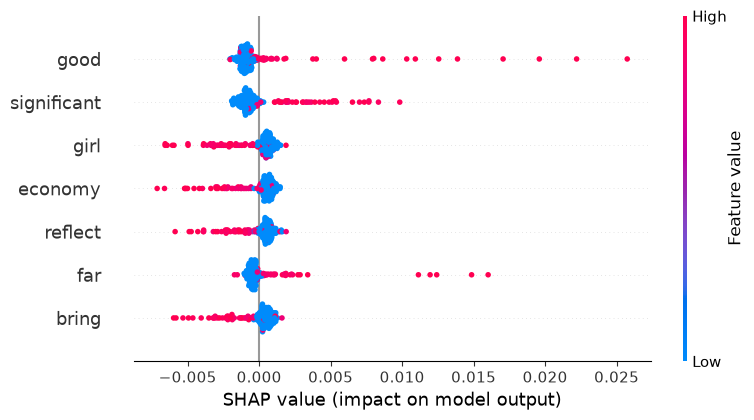

In [16]:
shap.summary_plot(sv_fake, X_shap, feature_names=list(feature_names), max_display=7)

In [17]:
shap_importance = pd.DataFrame({
    "term": feature_names,
    "mean_abs_shap": np.abs(sv_fake).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

shap_importance.head(7)

,term,mean_abs_shap
316,good,0.001715
683,significant,0.001406
311,girl,0.001091
220,economy,0.000986
618,reflect,0.000902
263,far,0.000899
97,bring,0.000891


The plot ranks the 7 terms with the largest average SHAP impact on the Random Forest's predictions, computed on a sample of 200 test articles. Each dot is one article. The table below gives the same ranking as numbers, using the average absolute SHAP value of each term, which shows the size of a term's effect but not its direction. Its position on the horizontal axis shows how much that term pushed the predicted probability of fake up (right) or down (left) for that article, and its color shows the term's TF-IDF weight in the article, with red meaning the term is frequent in that article and blue meaning it is absent or rare. Most dots are blue and sit close to zero, because most articles do not contain a given term, so the term has no effect on them. The effect comes from the smaller number of red dots. Reading those, terms such as good, significant, far, site, fire, mother, wrong, animal, stop, use, model and particular push toward fake when they appear, while girl, economy, reflect, bring, company, son, benefit and build push toward real.

The effects are very small. The largest push, for good, is about 0.025, or 2.5 percentage points of predicted probability, and for most terms the red dots stay within about 0.01, so no single term can move a prediction far. In the table, the highest average absolute SHAP value, for good, is only 0.0017, or about 0.17 percentage points of predicted probability, and the values fall off gradually down the list, with the last four terms (economy, reflect, far and bring) all within about 0.0001 of each other. This matches the weak recall and the small PFI drops seen above. The directions agree with the logistic regression baseline: significant, model, particular, wrong, fire, animal, far, good, site, mother and stop point toward fake, and economy, girl, reflect, bring and son toward real, so two very different models associate the same words with the same labels. Four terms here (company, use, benefit and build) do not appear among the baseline's top 15, and because SHAP is computed over all 5,000 terms rather than only the 30 chosen by chi-squared, it also brings up terms outside that list, such as company, use, son and benefit. The plot is based on only 200 articles, so terms with few red dots, such as use and benefit, are less certain than the more frequent ones, and it describes how the model uses each term, not whether the term makes an article fake.

## 10. Feature Effects (PDP)

As mentioned above, the top terms are not correlated with each other, so changing one term's value while holding the others fixed will not create unrealistic articles. This means PDP can be used here instead of ALE.

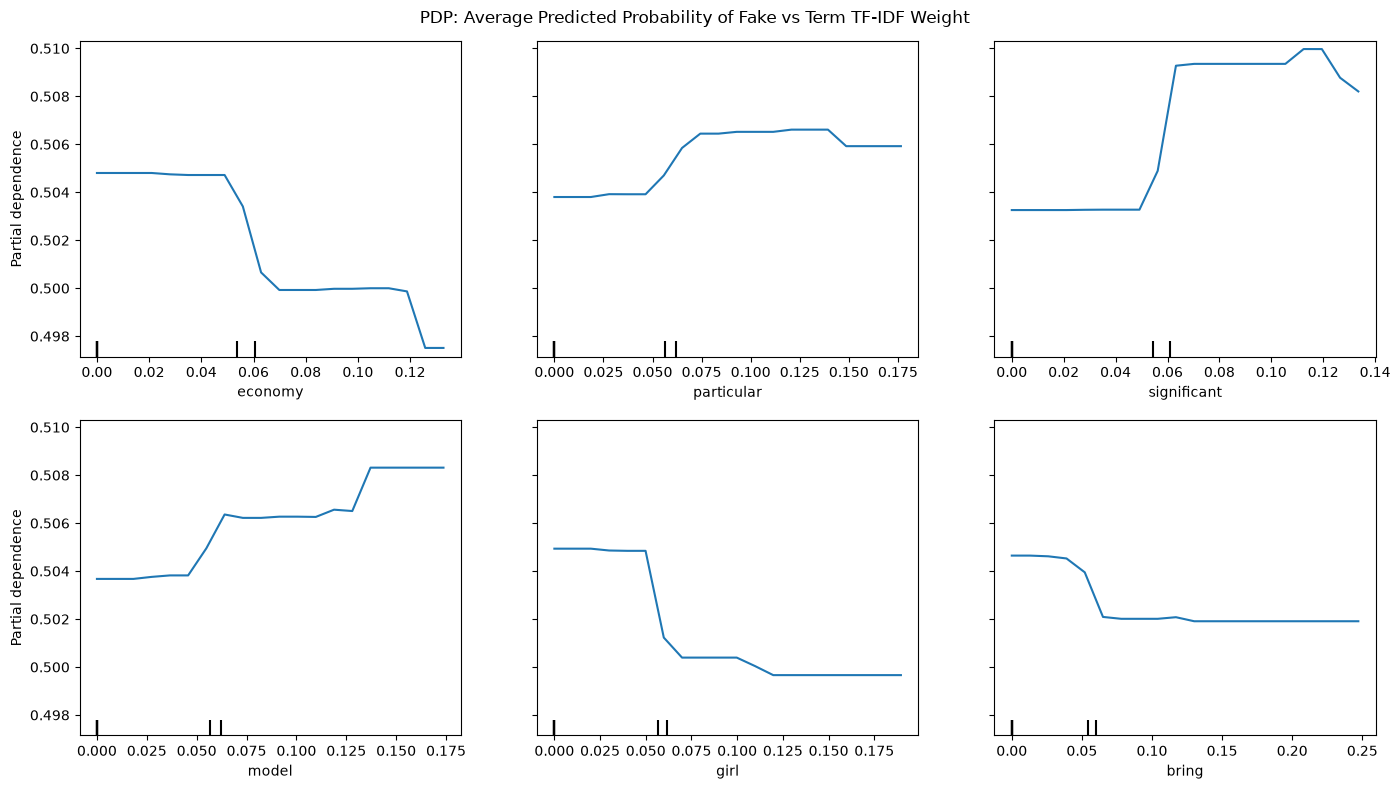

In [18]:
pdp_idx = list(top_idx[:6])

display = PartialDependenceDisplay.from_estimator(
    rf, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="average",
    grid_resolution=20,
    percentiles=(0, 1),       # TF-IDF is mostly zeros, so the default 5-95% range would collapse to a single value
    n_cols=3,
    random_state=RANDOM_STATE,
)
display.figure_.set_size_inches(14, 8)
display.figure_.suptitle("PDP: Average Predicted Probability of Fake vs Term TF-IDF Weight")
plt.tight_layout()
plt.show()

The plots show how the Random Forest's average predicted probability of fake changes as the TF-IDF weight of each of the six top terms increases. The directions are clear and consistent: when particular, significant and model are present, the average predicted probability of fake goes up, and when economy, girl and bring are present, it goes down. These are the same directions as the logistic regression coefficients and the SHAP plot, so three different methods agree on which words lean toward fake and which lean toward real. The curves are shaped like steps rather than smooth slopes: each stays flat near zero, changes sharply at a weight of about 0.05 to 0.07, and then stays almost flat. The tick marks along the bottom show that most articles have a weight of 0 for these terms and the rest start at around 0.055, so the step is simply the difference between an article that contains the term and one that does not. How heavily the term appears matters very little beyond that.

The effects are very small. All six plots share a vertical axis that runs only from about 0.498 to 0.510, and the largest changes, for economy and significant, are under 1 percentage point of predicted probability around a starting level of 50%, so no single term moves the model's average prediction far. This fits the weak recall, the tiny PFI drops and the small SHAP values seen above. The far right of some curves, such as the drop for economy near 0.125 and the decline for significant after 0.12, rests on very few articles, since the tick marks show that 90% of the sampled articles have a weight below about 0.06, so those parts should not be read closely.

## 11. Heterogeneity (ICE)

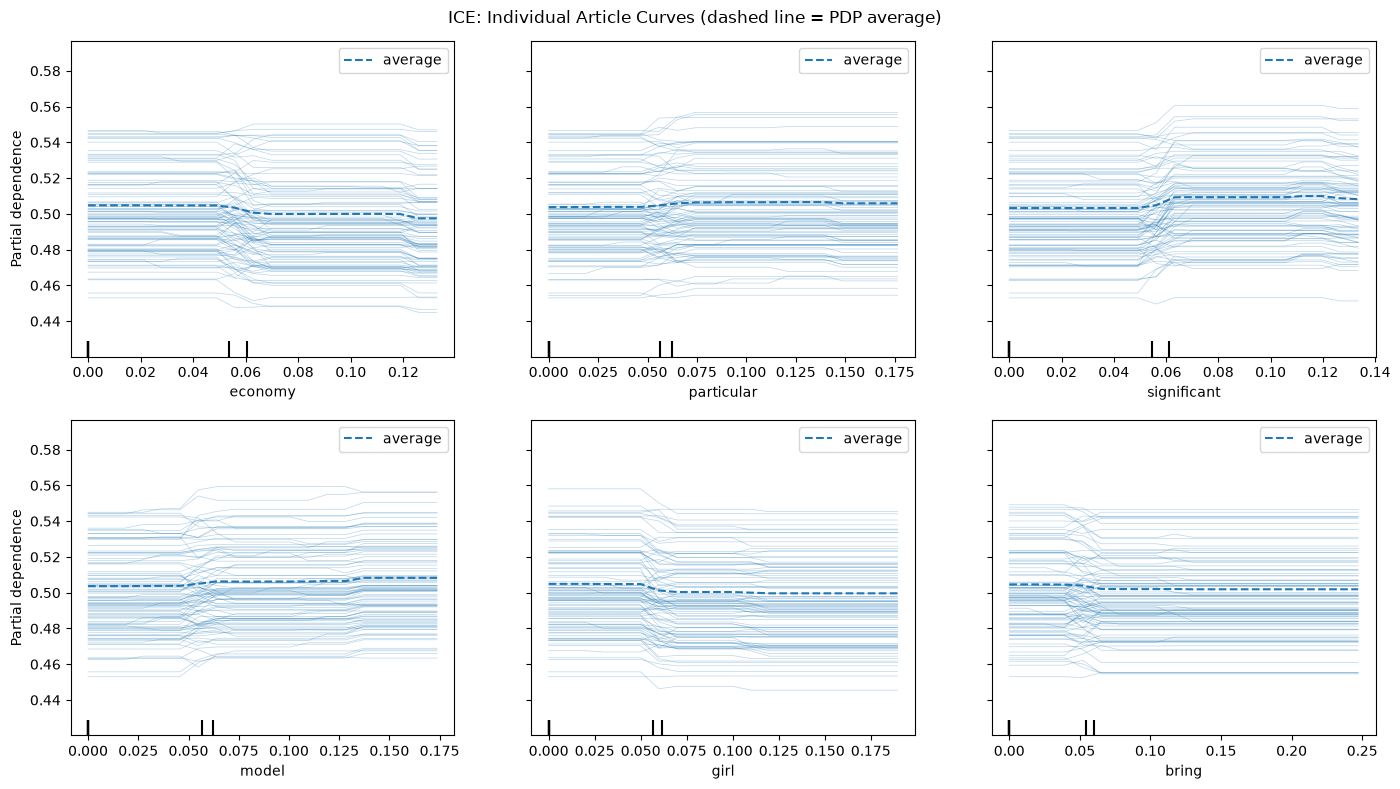

In [19]:
display = PartialDependenceDisplay.from_estimator(
    rf, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="both",
    subsample=100,
    grid_resolution=20,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
display.figure_.set_size_inches(14, 8)
display.figure_.suptitle("ICE: Individual Article Curves (dashed line = PDP average)")
plt.tight_layout()
plt.show()

The plots show the same six terms as the PDP, but with one thin line for each of 100 sampled articles instead of only the average, and the dashed line is the PDP average from before. The lines start at very different heights, from about 0.45 to 0.55, because each article's predicted probability also depends on all of its other terms. Most lines are flat, which means that for most articles, changing this one term does not change the prediction at all. The dashed average looks almost flat here only because the vertical axis is about ten times wider than in the PDP.

Around a weight of 0.05 to 0.07, where the term goes from absent to present, the lines fan out and cross. In every panel some articles move up, some move down, and some do not move, by a few percentage points in the larger cases. So the PDP step of under one percentage point is an average of larger moves in opposite directions: even for economy, whose average goes down, some articles go up, and even for significant, whose average goes up, some go down. Lines that cross instead of running parallel suggest that the effect of a term depends on the other terms in the article, so the PDP direction describes the typical article but not every article. The effects are still small, a few points around a starting level of 50%, which fits the weak recall seen earlier. Only 100 lines are drawn per panel, so individual lines should not be read closely.

## 12. Individual Decisions (LIME and SHAP)

So far we have looked at why the model makes its decisions as a whole (global). Now we pick specific scenarios and ask why the model made this particular decision. We look at three cases: a fake article the model caught correctly, a fake article it missed, and a real article it wrongly flagged as fake. LIME and SHAP are used to show which terms pushed each prediction toward fake or toward real.

### 12.1 LIME: Word-Removal Sanity Checks

LIME removes words from one article and watches how the predicted probability changes. Three cases are inspected: a correctly caught fake article (TP), a missed fake article (FN), and a real article wrongly flagged (FP). Weights are for the **fake** class: positive = pushes toward fake.

In [20]:
explainer_lime = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)

def predict_proba_text(texts):
    return rf.predict_proba(tfidf.transform(texts))

test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
y_true_arr = y_test.reset_index(drop=True).to_numpy()
y_pred_arr = np.asarray(y_pred)
proba_fake = rf.predict_proba(X_test)[:, 1]

tp = np.where((y_true_arr == 1) & (y_pred_arr == 1))[0]
fn = np.where((y_true_arr == 1) & (y_pred_arr == 0))[0]
fp = np.where((y_true_arr == 0) & (y_pred_arr == 1))[0]

cases = {
    "True Positive (fake, caught)":      tp[np.argmax(proba_fake[tp])],
    "False Negative (fake, missed)":     fn[np.argmin(proba_fake[fn])],
    "False Positive (real, flagged)":    fp[np.argmax(proba_fake[fp])],
}

True Positive (fake, caught) | P(fake) = 0.583


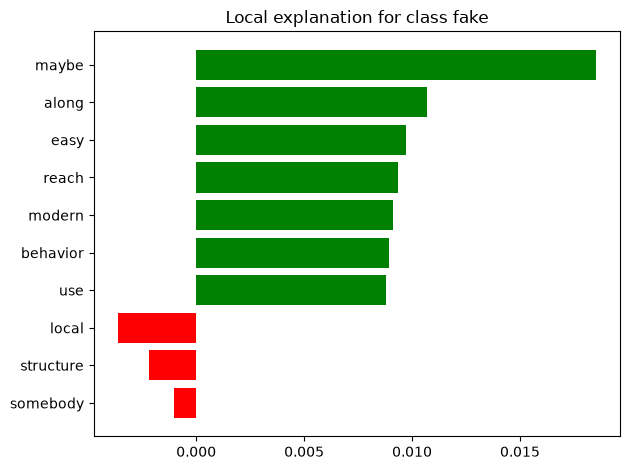

False Negative (fake, missed) | P(fake) = 0.425


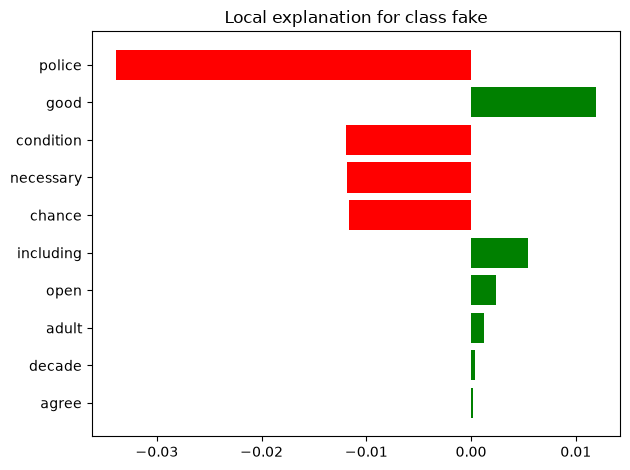

False Positive (real, flagged) | P(fake) = 0.572


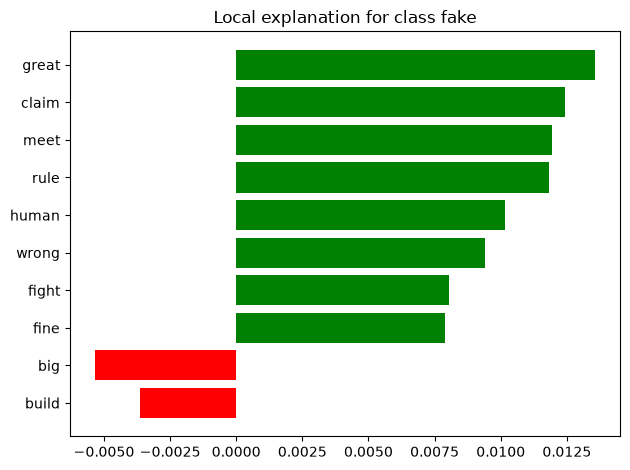

In [21]:
for name, i in cases.items():
    exp = explainer_lime.explain_instance(
        test_text.iloc[i], predict_proba_text,
        num_features=10, num_samples=1000, labels=(1,)
    )
    print(f"{name} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

For the fake article the model caught correctly (predicted probability of fake = 0.583), the plot shows which words pushed the prediction toward fake (green) or toward real (red), with each bar roughly the change in that probability when the word is removed. Seven of the ten words shown push toward fake, led by maybe at about 0.0185 (roughly 1.9 percentage points), followed by along, easy, reach, modern, behavior and use at about 0.009 to 0.011 each, while local, structure and somebody push weakly toward real. No single word dominates, so the prediction comes from many small pushes added together, which leaves it only just above the 0.5 cutoff. Apart from use, none of these words appeared in the global importance results above, and none is an obvious marker of fabricated reporting, so the model reached the right answer through ordinary words.

For the fake article the model missed (predicted probability of fake = 0.425, so it predicted real), the strongest bar is police, which pushes toward real by about 0.034, and condition, necessary and chance each add about 0.012 in the same direction. The words pushing toward fake, led by good at about 0.012 followed by including and open, are smaller and add up to less than half the pull toward real. The model therefore predicted real because this article contains several words it associates with real articles, and none of them (police, condition, necessary, chance) is a clear sign of trustworthy reporting. The miss was narrow (0.425 against a cutoff of 0.5) and looks like a result of chance word associations in the training data, not of anything that makes the article look real.

For the real article wrongly flagged as fake (predicted probability of fake = 0.572), eight of the ten words push toward fake, namely great, claim, meet, rule, human, wrong, fight and fine at about 0.008 to 0.0135 each, while only big and build push weakly toward real, by about 0.005 and 0.004. Wrong, big and build push in the same directions as in the earlier global results (wrong and big in the baseline coefficients, wrong and build in the SHAP summary), so the model is applying the same associations it uses elsewhere. None of these words is unusual for a real article, so the false alarm comes from many ordinary words adding up. Across all three cases the predicted probabilities (0.583, 0.425 and 0.572) stay within about 0.08 of the 0.5 cutoff, and the correctly caught fake article and the wrongly flagged real article receive almost the same score, so the model cannot separate them by confidence. Predictions are driven by small contributions from everyday words, with no single word deciding the outcome, which fits the weak recall seen throughout.

### 12.2 SHAP Waterfall (one article)

LIME explains one prediction by approximating the model around that article, whereas SHAP splits the model's own prediction into a starting value plus one contribution per term that adds up exactly to the final probability, so the waterfall serves as a second view to check against the LIME result.

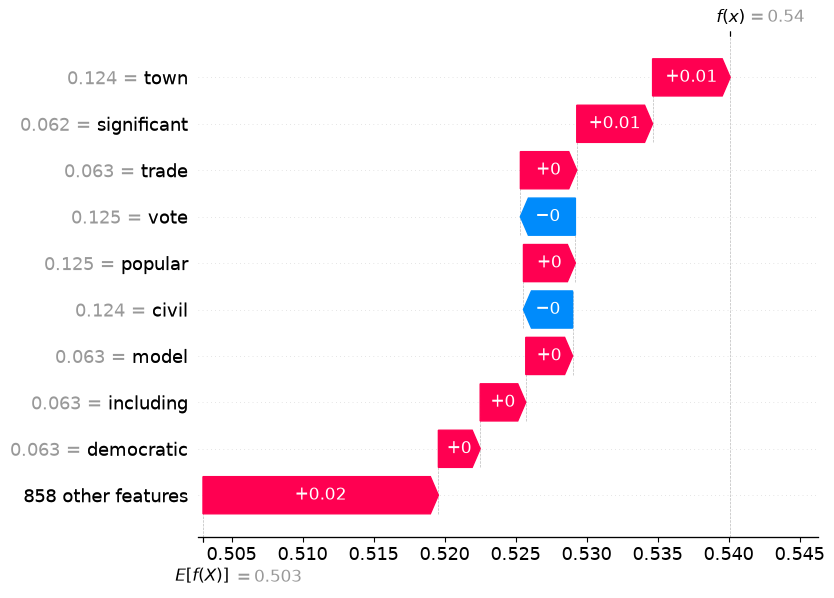

In [22]:
shap.plots.waterfall(
    shap.Explanation(
        values=sv_fake[0], base_values=base_value,
        data=X_shap[0], feature_names=list(feature_names)
    ),
    max_display=10
)

The waterfall starts at about 0.503, the average predicted probability of fake across the sampled articles, and each bar then adds or removes probability for one term until it reaches this article's prediction of 0.54. Red bars push toward fake and blue bars toward real, and the grey number beside each term is its TF-IDF weight in this article. Town and significant each add about 0.01, while trade, popular, model, including and democratic add less than 0.005 each (shown as +0), and vote and civil push very slightly toward real. The largest single bar is the combined effect of all the other terms, at about +0.02, so roughly half of the total push of 0.037 comes from terms too small to be shown one by one. This matches the global results, where significant and model push toward fake, and it shows the same pattern as the other plots: the prediction is built from many small contributions and no single term decides it. A final probability of 0.54, only slightly above the 0.503 average, also shows that the model is barely confident about this article.